# Retail Customer Shopping Behavior Analysis

## 1. Project Introduction

A retail store wants to understand its customers: who buys the most, which products sell best, and whether things like discounts, subscriptions, shipping and payment method are linked to how much customers spend.

In this project I:
- load the cleaned customer data from PostgreSQL
- explore and check the data
- answer 10 business questions with SQL
- draw charts with Matplotlib and Seaborn
- write down what I found

**Tools:** Python, Pandas, PostgreSQL, SQL, Matplotlib, Seaborn

## 2. Import Required Libraries

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

## 3. Connect to PostgreSQL

The password is stored in an environment variable called `PGPASSWORD`, so it is not written in the notebook.

In [2]:
password = os.environ["PGPASSWORD"]
engine = create_engine("postgresql+psycopg2://postgres:" + password + "@localhost:5432/customer_behavior")

## 4. Load Customer Data

In [3]:
df = pd.read_sql("select * from customer", engine)
print(df.shape)

(3900, 19)


## 5. Initial Data Exploration

First look at the data: the top rows, column types and basic statistics.

In [4]:
df.head()

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle_aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young_Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle_aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young_Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle_aged,365


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              3900 non-null   int64  
 1   age                      3900 non-null   int64  
 2   gender                   3900 non-null   object 
 3   item_purchased           3900 non-null   object 
 4   category                 3900 non-null   object 
 5   purchase_amount          3900 non-null   int64  
 6   location                 3900 non-null   object 
 7   size                     3900 non-null   object 
 8   color                    3900 non-null   object 
 9   season                   3900 non-null   object 
 10  review_rating            3900 non-null   float64
 11  subscription_status      3900 non-null   object 
 12  shipping_type            3900 non-null   object 
 13  discount_applied         3900 non-null   object 
 14  previous_purchases      

In [6]:
df.describe()

,customer_id,age,purchase_amount,review_rating,previous_purchases,purchase_frequency_days
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.750051,25.351538,89.133077
std,1125.977353,15.207589,23.685392,0.713590,14.447125,119.037566
min,1.000000,18.000000,20.000000,2.500000,1.000000,7.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000,14.000000
50%,1950.500000,44.000000,60.000000,3.800000,25.000000,30.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000,90.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000,365.000000


## 6. Data Cleaning

The main cleaning (missing ratings, column names, new columns) was already done in `customerProject.ipynb` before loading the data into PostgreSQL. Here I just check that the table is clean.

In [7]:
df.isnull().sum()

customer_id                0
age                        0
gender                     0
item_purchased             0
category                   0
purchase_amount            0
location                   0
size                       0
color                      0
season                     0
review_rating              0
subscription_status        0
shipping_type              0
discount_applied           0
previous_purchases         0
payment_method             0
frequency_of_purchases     0
age_group                  0
purchase_frequency_days    0
dtype: int64

In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer ids:", df["customer_id"].duplicated().sum())

Duplicate rows: 0
Duplicate customer ids: 0


There are no missing values and no duplicates, so nothing else needs to be fixed.

## 7. Exploratory Data Analysis

Quick counts and averages using Pandas.

In [9]:
df["gender"].value_counts()

gender
Male      2652
Female    1248
Name: count, dtype: int64

In [10]:
df["category"].value_counts()

category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64

In [11]:
df["subscription_status"].value_counts()

subscription_status
No     2847
Yes    1053
Name: count, dtype: int64

In [12]:
df["payment_method"].value_counts()

payment_method
PayPal           677
Credit Card      671
Cash             670
Debit Card       636
Venmo            634
Bank Transfer    612
Name: count, dtype: int64

In [13]:
df["age_group"].value_counts()

age_group
Young_Adult    1028
Middle_aged     986
Senior          944
Adult           942
Name: count, dtype: int64

In [14]:
df.groupby("category")["purchase_amount"].sum().sort_values(ascending=False)

category
Clothing       104264
Accessories     74200
Footwear        36093
Outerwear       18524
Name: purchase_amount, dtype: int64

In [15]:
df["review_rating"].corr(df["purchase_amount"])

0.029658742692550682

- Most customers are male.
- Clothing is the most common category.
- About a quarter of the customers have a subscription.
- The correlation between rating and purchase amount is close to 0, so they are not related.

## 8. SQL Business Analysis

Each query below answers one business question.

### Question 1: How much revenue does each gender bring in?

In [16]:
gender_revenue = pd.read_sql("""
select gender, count(*) as customers, sum(purchase_amount) as revenue, avg(purchase_amount) as avg_purchase
from customer
group by gender
order by revenue desc
""", engine)
gender_revenue["avg_purchase"] = gender_revenue["avg_purchase"].round(2)
gender_revenue

,gender,customers,revenue,avg_purchase
0,Male,2652,157890.0,59.54
1,Female,1248,75191.0,60.25


### Question 2: Who are the high-value customers?

I split purchase amounts into three equal-sized groups. The cut-off points come from the 33rd and 67th percentiles.

In [17]:
df["purchase_amount"].quantile([0.33, 0.67])

0.33    45.0
0.67    74.0
Name: purchase_amount, dtype: float64

In [18]:
spend_level = pd.read_sql("""
select case when purchase_amount >= 74 then 'High'
            when purchase_amount >= 45 then 'Medium'
            else 'Low' end as spend_level,
       count(*) as customers, sum(purchase_amount) as revenue
from customer
group by spend_level
order by revenue desc
""", engine)
spend_level["revenue_percent"] = (spend_level["revenue"] / spend_level["revenue"].sum() * 100).round(1)
spend_level

,spend_level,customers,revenue,revenue_percent
0,High,1297,113147.0,48.5
1,Medium,1356,80223.0,34.4
2,Low,1247,39711.0,17.0


### Question 3: Which product categories make the most sales?

In [19]:
category_sales = pd.read_sql("""
select category, count(*) as purchases, sum(purchase_amount) as revenue, avg(purchase_amount) as avg_purchase
from customer
group by category
order by revenue desc
""", engine)
category_sales["avg_purchase"] = category_sales["avg_purchase"].round(2)
category_sales["revenue_percent"] = (category_sales["revenue"] / category_sales["revenue"].sum() * 100).round(1)
category_sales

,category,purchases,revenue,avg_purchase,revenue_percent
0,Clothing,1737,104264.0,60.03,44.7
1,Accessories,1240,74200.0,59.84,31.8
2,Footwear,599,36093.0,60.26,15.5
3,Outerwear,324,18524.0,57.17,7.9


### Question 4: How do subscribers compare with non-subscribers?

In [20]:
subscription = pd.read_sql("""
select subscription_status, count(*) as customers, sum(purchase_amount) as revenue, avg(purchase_amount) as avg_purchase
from customer
group by subscription_status
""", engine)
subscription["avg_purchase"] = subscription["avg_purchase"].round(2)
subscription["revenue_percent"] = (subscription["revenue"] / subscription["revenue"].sum() * 100).round(1)
subscription

,subscription_status,customers,revenue,avg_purchase,revenue_percent
0,No,2847,170436.0,59.87,73.1
1,Yes,1053,62645.0,59.49,26.9


### Question 5: How are discounts used?

In [21]:
discount = pd.read_sql("""
select discount_applied, count(*) as customers, avg(purchase_amount) as avg_purchase
from customer
group by discount_applied
""", engine)
discount["avg_purchase"] = discount["avg_purchase"].round(2)
discount

,discount_applied,customers,avg_purchase
0,No,2223,60.13
1,Yes,1677,59.28


In [22]:
discount_category = pd.read_sql("""
select category, sum(case when discount_applied = 'Yes' then 1 else 0 end) * 100.0 / count(*) as percent_discounted
from customer
group by category
order by percent_discounted desc
""", engine)
discount_category["percent_discounted"] = discount_category["percent_discounted"].astype(float).round(1)
discount_category

,category,percent_discounted
0,Outerwear,44.4
1,Accessories,43.8
2,Footwear,43.2
3,Clothing,42.1


### Question 6: Which age groups bring in the most revenue?

In [23]:
age_revenue = pd.read_sql("""
select age_group, min(age) as youngest, max(age) as oldest, count(*) as customers,
       sum(purchase_amount) as revenue, avg(purchase_amount) as avg_purchase
from customer
group by age_group
order by youngest
""", engine)
age_revenue["avg_purchase"] = age_revenue["avg_purchase"].round(2)
age_revenue

,age_group,youngest,oldest,customers,revenue,avg_purchase
0,Young_Adult,18,31,1028,62143.0,60.45
1,Adult,32,44,942,55978.0,59.42
2,Middle_aged,45,57,986,59197.0,60.04
3,Senior,58,70,944,55763.0,59.07


### Question 7: How often do customers buy?

`purchase_frequency_days` is the number of days between purchases, so a smaller number means the customer buys more often.

In [24]:
frequency = pd.read_sql("""
select frequency_of_purchases, purchase_frequency_days, count(*) as customers, avg(purchase_amount) as avg_purchase
from customer
group by frequency_of_purchases, purchase_frequency_days
order by purchase_frequency_days
""", engine)
frequency["avg_purchase"] = frequency["avg_purchase"].round(2)
frequency

,frequency_of_purchases,purchase_frequency_days,customers,avg_purchase
0,Weekly,7,539,58.97
1,Bi-Weekly,14,547,60.69
2,Fortnightly,14,542,59.05
3,Monthly,30,553,59.33
4,Quarterly,90,563,59.98
5,Every 3 Months,90,584,60.08
6,Annually,365,572,60.17


In [25]:
age_frequency = pd.read_sql("""
select age_group, avg(purchase_frequency_days) as avg_days_between_purchases
from customer
group by age_group
order by min(age)
""", engine)
age_frequency["avg_days_between_purchases"] = age_frequency["avg_days_between_purchases"].round(1)
age_frequency

,age_group,avg_days_between_purchases
0,Young_Adult,84.0
1,Adult,92.8
2,Middle_aged,83.6
3,Senior,96.8


### Question 8: How are products rated?

In [26]:
category_rating = pd.read_sql("""
select category, avg(review_rating) as avg_rating
from customer
group by category
order by avg_rating desc
""", engine)
category_rating["avg_rating"] = category_rating["avg_rating"].round(2)
category_rating

,category,avg_rating
0,Footwear,3.79
1,Accessories,3.77
2,Outerwear,3.75
3,Clothing,3.72


In [27]:
top_rated = pd.read_sql("""
select item_purchased, avg(review_rating) as avg_rating, count(*) as orders
from customer
group by item_purchased
having count(*) >= 30
order by avg_rating desc
limit 10
""", engine)
top_rated["avg_rating"] = top_rated["avg_rating"].round(2)
top_rated

,item_purchased,avg_rating,orders
0,Gloves,3.86,140
1,Sandals,3.84,160
2,Boots,3.82,144
3,Hat,3.80,154
4,Skirt,3.78,158
5,T-shirt,3.78,147
6,Handbag,3.78,153
7,Belt,3.76,161
8,Jacket,3.76,163
9,Sweater,3.76,164


### Question 9: Which shipping types and payment methods bring in the most revenue?

In [28]:
shipping = pd.read_sql("""
select shipping_type, count(*) as customers, sum(purchase_amount) as revenue, avg(purchase_amount) as avg_purchase
from customer
group by shipping_type
order by revenue desc
""", engine)
shipping["avg_purchase"] = shipping["avg_purchase"].round(2)
shipping

,shipping_type,customers,revenue,avg_purchase
0,Free Shipping,675,40777.0,60.41
1,Express,646,39067.0,60.48
2,Store Pickup,650,38931.0,59.89
3,Standard,654,38233.0,58.46
4,2-Day Shipping,627,38080.0,60.73
5,Next Day Air,648,37993.0,58.63


In [29]:
payment = pd.read_sql("""
select payment_method, count(*) as customers, sum(purchase_amount) as revenue, avg(purchase_amount) as avg_purchase
from customer
group by payment_method
order by revenue desc
""", engine)
payment["avg_purchase"] = payment["avg_purchase"].round(2)
payment

,payment_method,customers,revenue,avg_purchase
0,Credit Card,671,40310.0,60.07
1,PayPal,677,40109.0,59.25
2,Cash,670,40002.0,59.70
3,Debit Card,636,38742.0,60.92
4,Venmo,634,37374.0,58.95
5,Bank Transfer,612,36544.0,59.71


### Question 10: Do we have repeat customers?

Every customer appears only once and there are no purchase dates, so real repeat buying cannot be measured. I use `previous_purchases` instead: 1 means a first-time buyer, more than 1 means a repeat buyer.

In [30]:
repeat = pd.read_sql("""
select case when previous_purchases = 1 then 'First purchase' else 'Repeat' end as customer_type,
       count(*) as customers, sum(purchase_amount) as revenue
from customer
group by customer_type
order by customers desc
""", engine)
repeat["customer_percent"] = (repeat["customers"] / repeat["customers"].sum() * 100).round(1)
repeat

,customer_type,customers,revenue,customer_percent
0,Repeat,3817,228228.0,97.9
1,First purchase,83,4853.0,2.1


## 9. Python Data Visualizations

### Customer overview

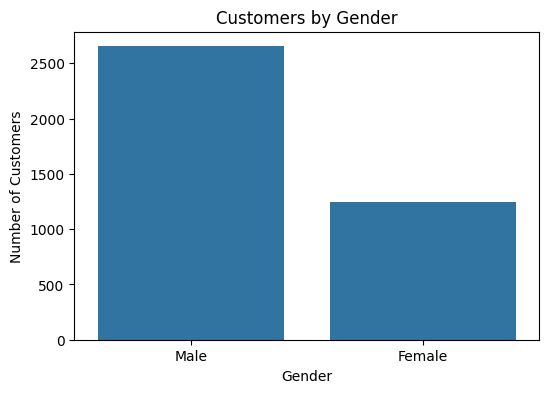

In [31]:
plt.figure(figsize=(6, 4))
sns.countplot(x="gender", data=df)
plt.title("Customers by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.show()

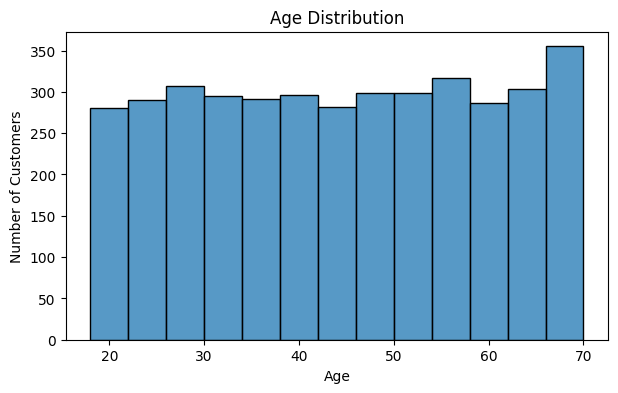

In [32]:
plt.figure(figsize=(7, 4))
sns.histplot(df["age"], bins=13)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

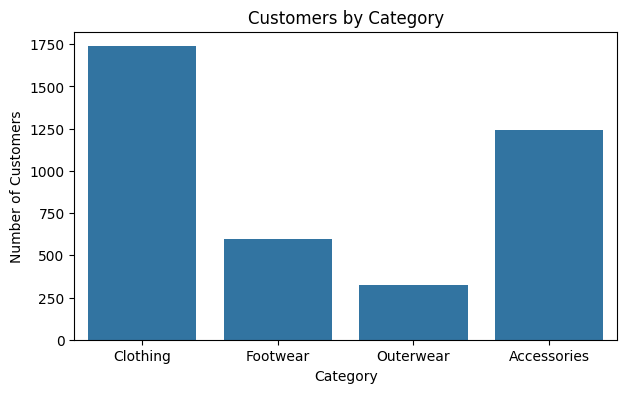

In [33]:
plt.figure(figsize=(7, 4))
sns.countplot(x="category", data=df)
plt.title("Customers by Category")
plt.xlabel("Category")
plt.ylabel("Number of Customers")
plt.show()

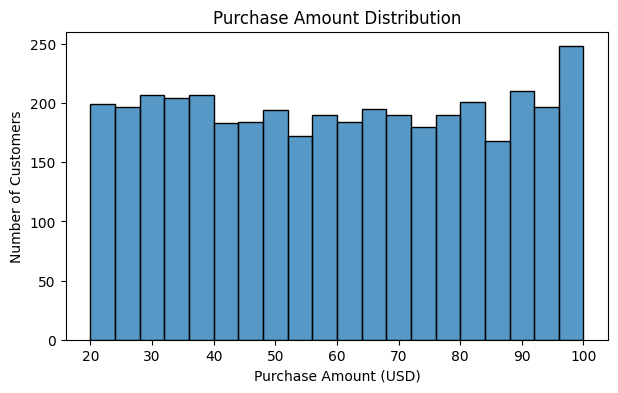

In [34]:
plt.figure(figsize=(7, 4))
sns.histplot(df["purchase_amount"], bins=20)
plt.title("Purchase Amount Distribution")
plt.xlabel("Purchase Amount (USD)")
plt.ylabel("Number of Customers")
plt.show()

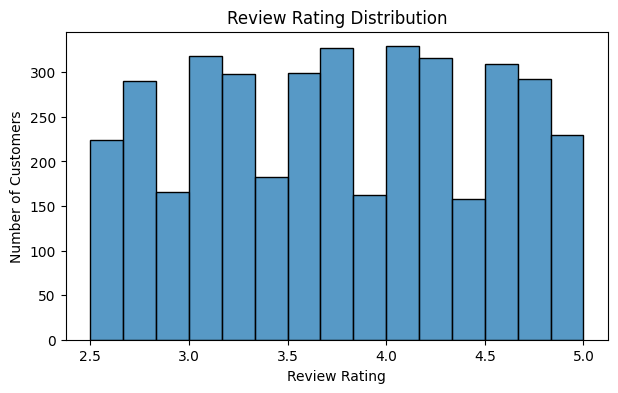

In [35]:
plt.figure(figsize=(7, 4))
sns.histplot(df["review_rating"], bins=15)
plt.title("Review Rating Distribution")
plt.xlabel("Review Rating")
plt.ylabel("Number of Customers")
plt.show()

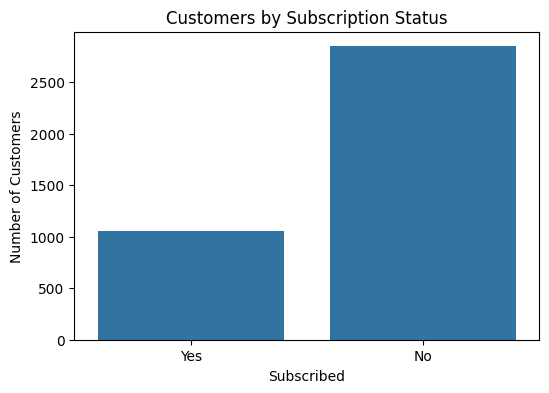

In [36]:
plt.figure(figsize=(6, 4))
sns.countplot(x="subscription_status", data=df)
plt.title("Customers by Subscription Status")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")
plt.show()

### Revenue

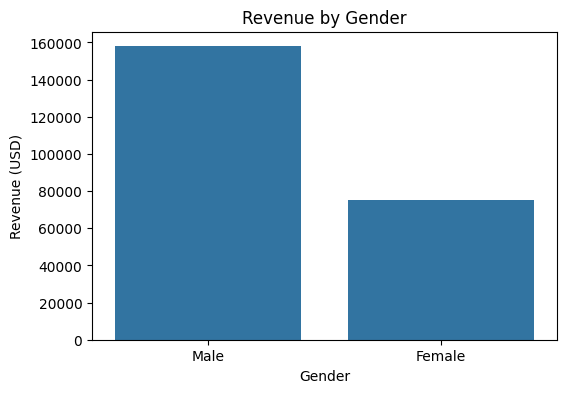

In [37]:
plt.figure(figsize=(6, 4))
sns.barplot(x="gender", y="revenue", data=gender_revenue)
plt.title("Revenue by Gender")
plt.xlabel("Gender")
plt.ylabel("Revenue (USD)")
plt.show()

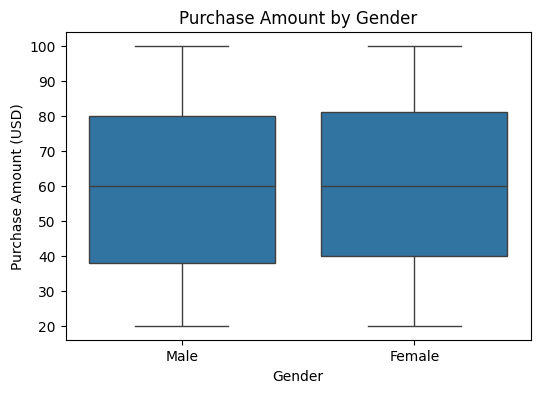

In [38]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="gender", y="purchase_amount", data=df)
plt.title("Purchase Amount by Gender")
plt.xlabel("Gender")
plt.ylabel("Purchase Amount (USD)")
plt.show()

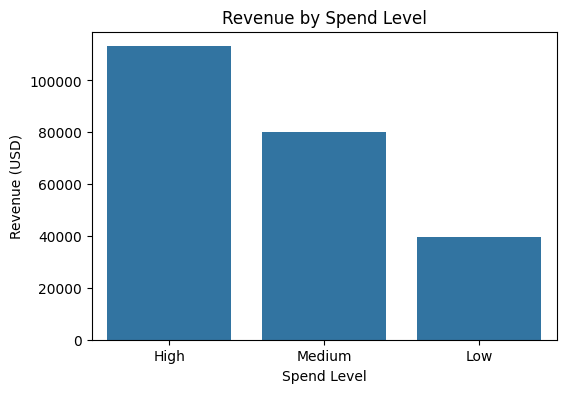

In [39]:
plt.figure(figsize=(6, 4))
sns.barplot(x="spend_level", y="revenue", data=spend_level)
plt.title("Revenue by Spend Level")
plt.xlabel("Spend Level")
plt.ylabel("Revenue (USD)")
plt.show()

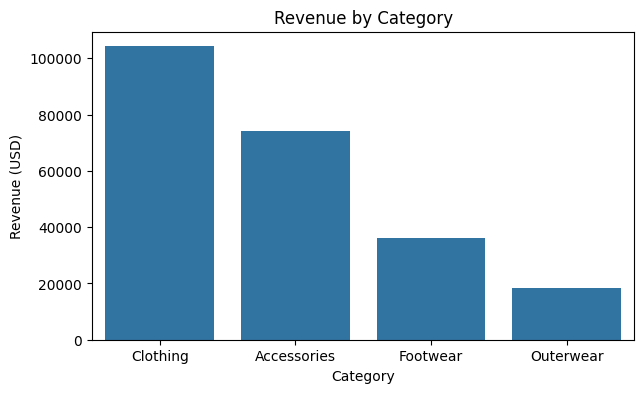

In [40]:
plt.figure(figsize=(7, 4))
sns.barplot(x="category", y="revenue", data=category_sales)
plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (USD)")
plt.show()

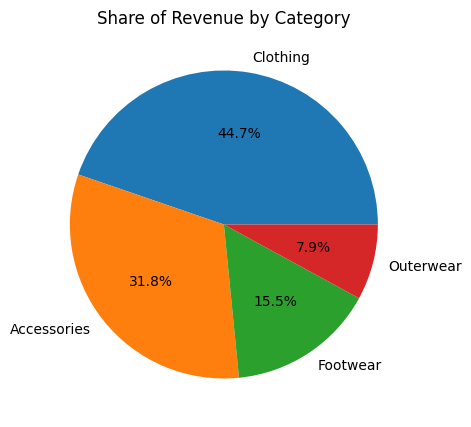

In [41]:
plt.figure(figsize=(5, 5))
plt.pie(category_sales["revenue"], labels=category_sales["category"], autopct="%1.1f%%")
plt.title("Share of Revenue by Category")
plt.show()

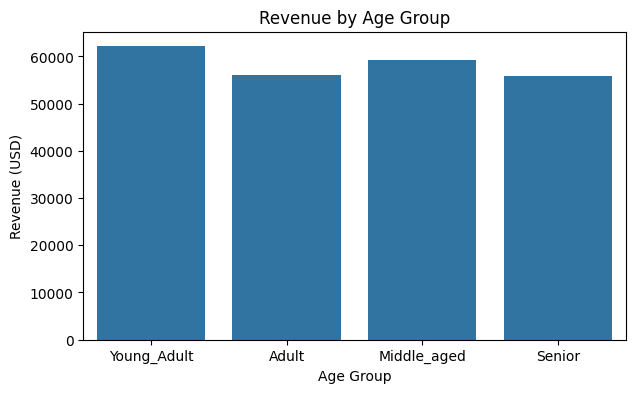

In [42]:
plt.figure(figsize=(7, 4))
sns.barplot(x="age_group", y="revenue", data=age_revenue)
plt.title("Revenue by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Revenue (USD)")
plt.show()

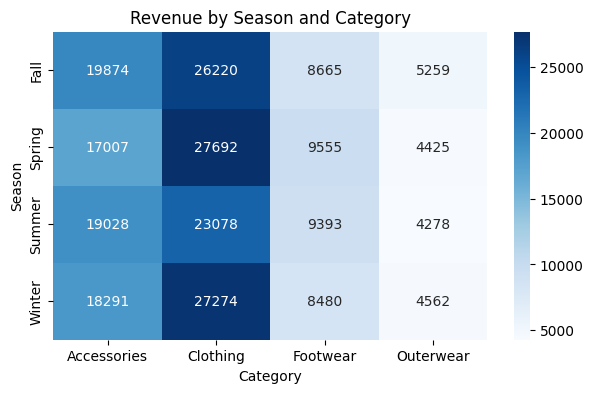

In [43]:
season_category = df.pivot_table(index="season", columns="category", values="purchase_amount", aggfunc="sum")
plt.figure(figsize=(7, 4))
sns.heatmap(season_category, annot=True, fmt=".0f", cmap="Blues")
plt.title("Revenue by Season and Category")
plt.xlabel("Category")
plt.ylabel("Season")
plt.show()

### Shopping behavior

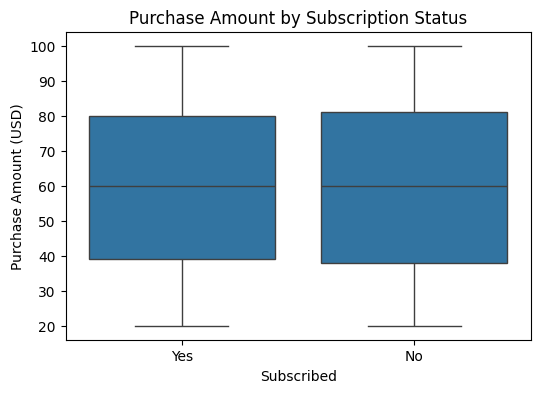

In [44]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="subscription_status", y="purchase_amount", data=df)
plt.title("Purchase Amount by Subscription Status")
plt.xlabel("Subscribed")
plt.ylabel("Purchase Amount (USD)")
plt.show()

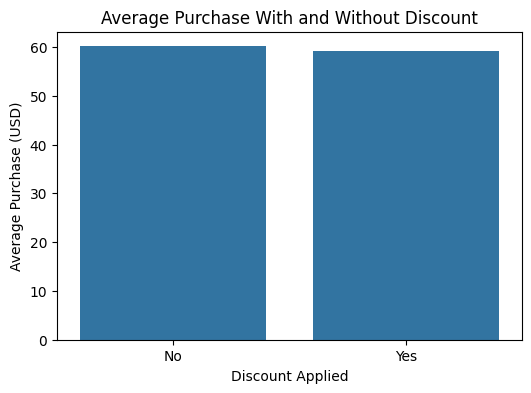

In [45]:
plt.figure(figsize=(6, 4))
sns.barplot(x="discount_applied", y="avg_purchase", data=discount)
plt.title("Average Purchase With and Without Discount")
plt.xlabel("Discount Applied")
plt.ylabel("Average Purchase (USD)")
plt.show()

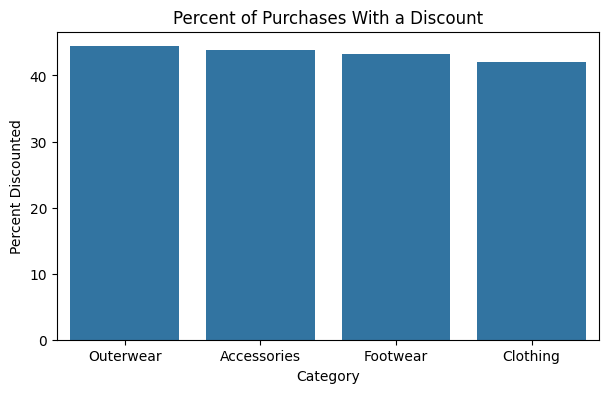

In [46]:
plt.figure(figsize=(7, 4))
sns.barplot(x="category", y="percent_discounted", data=discount_category)
plt.title("Percent of Purchases With a Discount")
plt.xlabel("Category")
plt.ylabel("Percent Discounted")
plt.show()

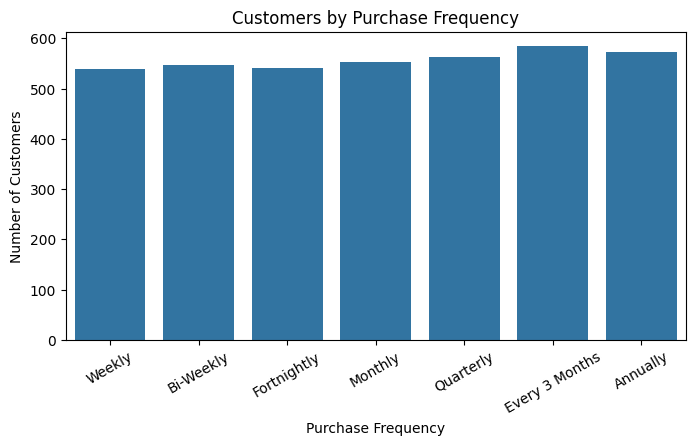

In [47]:
plt.figure(figsize=(8, 4))
sns.barplot(x="frequency_of_purchases", y="customers", data=frequency)
plt.title("Customers by Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.show()

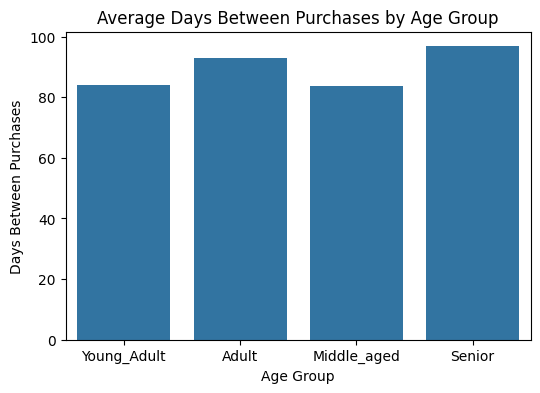

In [48]:
plt.figure(figsize=(6, 4))
sns.barplot(x="age_group", y="avg_days_between_purchases", data=age_frequency)
plt.title("Average Days Between Purchases by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Days Between Purchases")
plt.show()

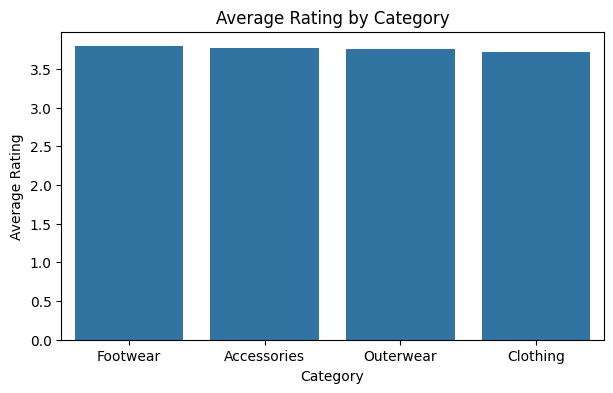

In [49]:
plt.figure(figsize=(7, 4))
sns.barplot(x="category", y="avg_rating", data=category_rating)
plt.title("Average Rating by Category")
plt.xlabel("Category")
plt.ylabel("Average Rating")
plt.show()

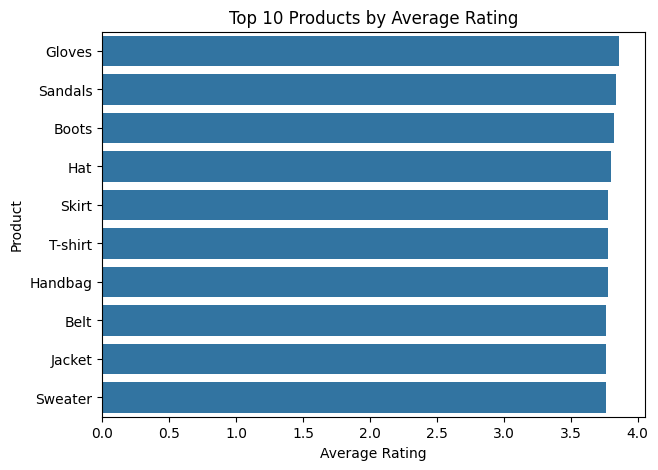

In [50]:
plt.figure(figsize=(7, 5))
sns.barplot(x="avg_rating", y="item_purchased", data=top_rated)
plt.title("Top 10 Products by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Product")
plt.show()

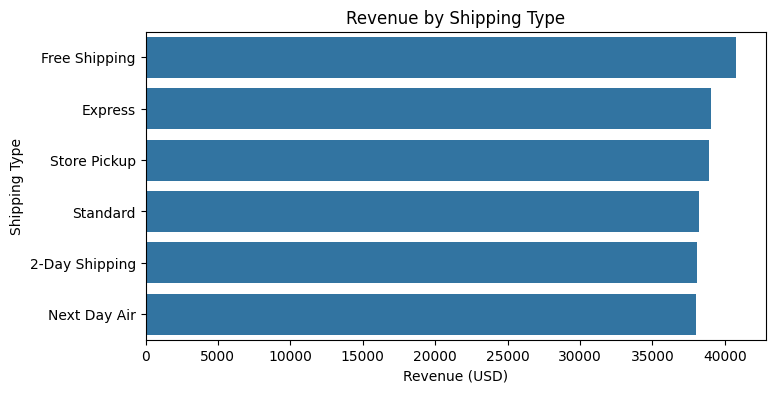

In [51]:
plt.figure(figsize=(8, 4))
sns.barplot(x="revenue", y="shipping_type", data=shipping)
plt.title("Revenue by Shipping Type")
plt.xlabel("Revenue (USD)")
plt.ylabel("Shipping Type")
plt.show()

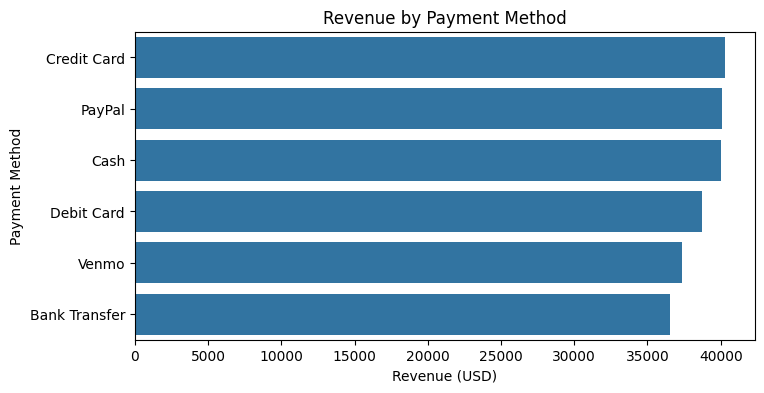

In [52]:
plt.figure(figsize=(8, 4))
sns.barplot(x="revenue", y="payment_method", data=payment)
plt.title("Revenue by Payment Method")
plt.xlabel("Revenue (USD)")
plt.ylabel("Payment Method")
plt.show()

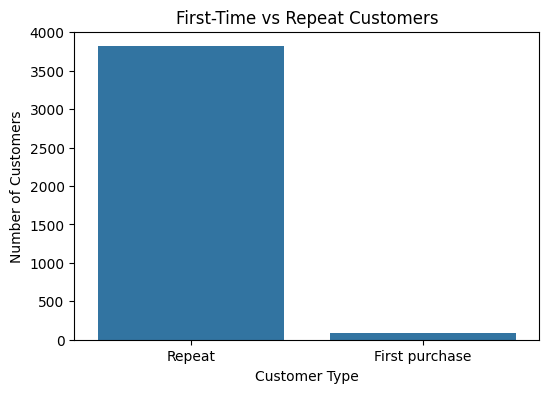

In [53]:
plt.figure(figsize=(6, 4))
sns.barplot(x="customer_type", y="customers", data=repeat)
plt.title("First-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.show()

## 10. Business Insights

**Revenue by gender:** Male customers bring in $157,890 (67.7%) and female customers $75,191. The average purchase is almost the same ($59.54 for men, $60.25 for women), so the difference is the number of customers, not how much each one spends.

**High-value customers:** Customers who spend $74 or more are about a third of all customers but bring in 48.5% of revenue. The low spenders (under $45) bring in only 17.0%.

**Categories:** Clothing is the top category with $104,264 (44.7% of revenue), followed by Accessories (31.8%), Footwear (15.5%) and Outerwear (7.9%). Outerwear also has the lowest average purchase ($57.17).

**Subscription:** 1,053 customers (27%) are subscribers and they bring in 26.9% of revenue. Their average purchase ($59.49) is about the same as non-subscribers ($59.87). In this data every subscriber is male and also has a discount, so I cannot say the subscription itself changes spending.

**Discounts:** 1,677 customers (43%) had a discount. Their average purchase is $59.28 compared with $60.13 without a discount, so discounts are not linked to bigger purchases. The share of discounted purchases is similar in every category (42.1% to 44.4%).

**Age groups:** Young adults (18 to 31) bring in the most revenue ($62,143) and seniors (58 to 70) the least ($55,763), but the groups are close. On average, middle-aged customers (83.6 days) and young adults (84.0 days) buy a little more often than seniors (96.8 days).

**Frequency:** Customers are spread evenly across the seven frequency labels (539 to 584 customers each) and their average purchase hardly changes.

**Ratings:** Average ratings by category are between 3.72 and 3.79. The best rated products are Gloves (3.86), Sandals (3.84) and Boots (3.82). The correlation between rating and purchase amount is 0.03, so ratings are not related to how much customers spend.

**Shipping and payment:** Free Shipping has the highest revenue ($40,777) and Standard shipping the lowest average purchase ($58.46). Credit Card ($40,310), PayPal ($40,109) and Cash ($40,002) are almost equal, and Bank Transfer is lowest ($36,544).

**Repeat customers:** 3,817 customers (97.9%) have more than one previous purchase and only 83 have one. Because almost everyone is a repeat customer, this does not help to split customers into groups.

**What the business could consider:** try marketing aimed at women (same spend per purchase, but fewer customers), keep the high-spend customers happy, look at the Outerwear range and prices, and test discounts and subscriptions before spending more on them. These are patterns in the data and do not prove cause and effect.

## 11. Final Conclusion

I loaded 3,900 customers from PostgreSQL, checked the data, answered 10 business questions with SQL and drew charts for each answer.

The main findings are that most revenue comes from male customers, from the customers who spend $74 or more, and from the Clothing and Accessories categories. Most other comparisons (age, shipping, payment, frequency, ratings) show only small differences.

**Limitations**
- There is no date column, so I cannot look at trends or measure real repeat buying.
- All female customers have no subscription and no discount, and all subscribers are male with a discount, so the effects of gender, subscription and discount cannot be separated.
- The differences between most groups are small.
- "Bi-Weekly" and "Fortnightly" were both turned into 14 days when the data was cleaned.

**Next steps:** get data with purchase dates, and test discounts and subscriptions on real customers before drawing conclusions about their effect.